## Командная работа по теме: "Турецкая недвижимость🏩". Выполняли: Муфтахутдинов Алмаз, Воробьев Артем.

### Подключение библиотек📙

In [10]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np
from sklearn.cluster import KMeans, AgglomerativeClustering
import time
import re
import pandas as pd
from tqdm.auto import tqdm
from deep_translator import GoogleTranslator
import os
import subprocess
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

In [11]:
df = pd.read_csv('real_estate_data_ru.csv')

In [12]:
df.head()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.0,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.0,İstanbul/Beşiktaş/Levent,NaN,Fancoil,32500000.0,TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,1450000.0,TRY


In [75]:
df.describe()

,id,listing_type,tom,size,furnished,price
count,403487.00000,403487.000000,403487.000000,257481.000000,0.0,4.027720e+05
mean,201744.00000,1.294235,57.022739,279.349094,NaN,3.546417e+05
std,116476.80837,0.467733,44.358933,9429.195331,NaN,4.809503e+06
min,1.00000,1.000000,0.000000,1.000000,NaN,-2.500000e+02
25%,100872.50000,1.000000,29.000000,85.000000,NaN,2.500000e+03
50%,201744.00000,1.000000,40.000000,110.000000,NaN,1.990000e+05
75%,302615.50000,2.000000,90.000000,140.000000,NaN,3.420000e+05
max,403487.00000,3.000000,180.000000,948235.000000,NaN,2.000000e+09


In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  str    
 2   sub_type           403487 non-null  str    
 3   start_date         403487 non-null  str    
 4   end_date           266298 non-null  str    
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  str    
 8   total_floor_count  375466 non-null  str    
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  str    
 11  size               257481 non-null  float64
 12  address            403487 non-null  str    
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  str    
 15  price              402772 non-null  float64
 16  price_currenc

- id - уникальный идентификатор недвижимости
- type - тип недвижимости
- sub_type - уточняющий тип недвижимости
- start_date - дата публикации объявления
- end_date - дата завершения объявления
- listing_type - тип предложения (аренда/продажа)
- tom - уникальный идентификатор земельного участка (в Турции)
- building_age - год постройки
- total_floor_count - общее количество этажей
- floor_no - этаж, на котором находится недвижимость
- room_count - количество комнат
- size - размер недвижимости
- address - адрес недвижимости
- furnished - статус меблеровки (0 - нет мебели / 1 - есть мебель)
- heating_type - тип отопления в недвижимости
- price - цена
- price_currency - валюта цены

In [77]:
df.duplicated().sum()

np.int64(0)

Дубликаты в датасете отсутствуют

In [78]:
df.isnull().sum()

id                        0
type                      0
sub_type                  0
start_date                0
end_date             137189
listing_type              0
tom                       0
building_age          27390
total_floor_count     28021
floor_no              35296
room_count                0
size                 146006
address                   0
furnished            403487
heating_type          27970
price                   715
price_currency          715
dtype: int64

### В датасете отсутствуют многие значения. Также колонка с мебелированием полностью пустая. Смысла восстанавливать её нет, поэтому приходим к выводу, что её лучше будет удалить из датасета, это не сильно повлияет на будущий анализ

### Перевод Датасета

In [79]:
subprocess.check_call([sys.executable, "-m", "pip", "install", "deep-translator"])
subprocess.check_call([sys.executable, "-m", "pip", "install", "tqdm"])

0

In [80]:
df = df.drop(columns=['furnished'], errors='ignore')

addr_parts = df['address'].str.split('/', expand=True)
addr_parts.columns = ['провинция', 'район', 'квартал']
df = pd.concat([df.drop(columns=['address']), addr_parts], axis=1)

existing_columns = [
    'type', 'sub_type', 'heating_type', 'price_currency',
    'building_age', 'total_floor_count', 'floor_no', 'room_count',
    'провинция', 'район', 'квартал',
]

In [81]:
unique_texts = {}
for col in existing_columns:
    for val in df[col].dropna().unique():
        val_str = str(val).strip()
        if val_str and val_str not in unique_texts:
            unique_texts[val_str] = None

test_mode = False
if test_mode:
    unique_items = list(unique_texts.items())[:100]
else:
    unique_items = list(unique_texts.items())
    print(f"Всего значений: {len(unique_items)}")

Всего значений: 5372


In [82]:
translator = GoogleTranslator(source='tr', target='ru')

error_count = 0
success_count = 0
start_time = time.time()

for idx, (text, _) in enumerate(tqdm(unique_items, desc="Перевод")):
    try:
        result = translator.translate(text)
        unique_texts[text] = result if result else text
        success_count += 1

        if idx % 5 == 0:
            time.sleep(0.1)

    except Exception as e:
        error_count += 1
        unique_texts[text] = '[ОШИБКА]'
        if error_count <= 3:
            print(f'Ошибка: {text!r} -> {e}')

    elapsed = time.time() - start_time
    minutes = int(elapsed // 60)
    seconds = int(elapsed % 60)

print(f'\nГотово за {minutes}м {seconds}с')
print(f'Успешно: {success_count}, ошибок: {error_count}')
for col in existing_columns:
    df[f'{col}_ru'] = df[col].astype(str).map(unique_texts).fillna('')
for idx in range(min(5, len(df))):
    print(f"\nСтрока {idx+1}:")
    for col in existing_columns[:3]:
        original = df.iloc[idx][col]
        translated = df.iloc[idx][f'{col}_ru']
        print(f"  {col}: {original} → {translated}")
output_file = 'real_estate_data_ru.csv'
df.to_csv(output_file, index=False, encoding='utf-8-sig')
print(f"\nСохранено: {output_file}")
print(f"{len(df):,} строк × {len(df.columns)} столбцов")

Перевод:   0%|          | 0/5372 [00:00<?, ?it/s]

Ошибка: 'Konut' -> Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function
Ошибка: 'Rezidans' -> Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function
Ошибка: 'Daire' -> Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function


KeyboardInterrupt: 

In [13]:
df_tr = pd.read_csv('real_estate_data_ru2.csv')

In [14]:
df_tr.head()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,heating_type,price,price_currency,city,district,neighborhood
0,1,Жильё,Резиденция,12/10/18,1/9/19,Аренда,30,0,20 и более,2,2+1,90.0,Фанкойл,3500.0,TRY,Стамбул,Kartal,Kordonboyu
1,2,Жильё,Квартира,2/13/19,NaN,Продажа,14,0,20 и более,20 и более,1+0,43.0,Фанкойл,490000.0,TRY,Стамбул,Kartal,Kordonboyu
2,3,Жильё,Квартира,10/9/18,11/8/18,Продажа,30,0,1,Высокий первый этаж,2+1,NaN,Фанкойл,155000.0,TRY,Текирдаг,Çorlu,Reşadiye
3,4,Жильё,Резиденция,9/10/18,10/10/18,Продажа,30,3,20 и более,20 и более,6+1,450.0,Фанкойл,32500000.0,TRY,Стамбул,Beşiktaş,Levent
4,5,Жильё,Резиденция,12/10/18,1/9/19,Продажа,30,0,20 и более,2,2+1,90.0,Фанкойл,1450000.0,TRY,Стамбул,Kartal,Kordonboyu


In [15]:
df_tr.describe()

,id,tom,size,price
count,403487.00000,403487.000000,257481.000000,4.027720e+05
mean,201744.00000,57.022739,279.349094,3.546417e+05
std,116476.80837,44.358933,9429.195331,4.809503e+06
min,1.00000,0.000000,1.000000,-2.500000e+02
25%,100872.50000,29.000000,85.000000,2.500000e+03
50%,201744.00000,40.000000,110.000000,1.990000e+05
75%,302615.50000,90.000000,140.000000,3.420000e+05
max,403487.00000,180.000000,948235.000000,2.000000e+09


In [16]:
df_tr.isnull().sum()

id                        0
type                      0
sub_type                  0
start_date                0
end_date             137189
listing_type              0
tom                       0
building_age          27390
total_floor_count     28021
floor_no              35296
room_count                0
size                 146006
heating_type              0
price                   715
price_currency          715
city                      0
district                  7
neighborhood             16
dtype: int64

In [17]:
df_tr.info()

<class 'pandas.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  str    
 2   sub_type           403487 non-null  str    
 3   start_date         403487 non-null  str    
 4   end_date           266298 non-null  str    
 5   listing_type       403487 non-null  str    
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  str    
 8   total_floor_count  375466 non-null  str    
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  str    
 11  size               257481 non-null  float64
 12  heating_type       403487 non-null  str    
 13  price              402772 non-null  float64
 14  price_currency     402772 non-null  str    
 15  city               403487 non-null  str    
 16  district     

### Удаление аномалий и очистки датасета

In [18]:
print(f"Размер до очистки: {df_tr.shape}")

Размер до очистки: (403487, 18)


In [19]:
# Отрицательные цены = NaN
df_tr.loc[df_tr['price'] <= 0, 'price'] = np.nan

# Нереалистичная площадь = NaN (не удаляем строку, просто помечаем)
df_tr.loc[(df_tr['size'] < 10) | (df_tr['size'] > 1000), 'size'] = np.nan
print(f"\nПропусков в price: {df_tr['price'].isnull().sum()}")
print(f"Пропусков в size: {df_tr['size'].isnull().sum()}")


Пропусков в price: 760
Пропусков в size: 147078


In [20]:
# Удаляем экстремальные выбросы цены (выше 99-го перцентиля)
price_limit = df_tr['price'].quantile(0.99)
print(f"Удаляем {len(df_tr[df_tr['price'] > price_limit])} выбросов (цена > {price_limit:,.0f} TRY)")

df_tr = df_tr[df_tr['price'] <= price_limit].copy()

# Также удаляем отрицательные цены и нулевую площадь
df_tr = df_tr[(df_tr['price'] > 0) & (df_tr['size'] > 0)].copy()

print(f"Размер датасета после очистки: {df_tr.shape}")

Удаляем 4010 выбросов (цена > 2,850,000 TRY)
Размер датасета после очистки: (253886, 18)


In [21]:
replacements = {
    '20 и более': 20,
    'Высокий первый этаж': 1,
    'Yüksek Giriş': 1,        # на всякий случай, если осталось после перевода
    '20 ve üzeri': 20           # тоже самое      
}
cols_to_fix = ['building_age', 'total_floor_count', 'floor_no']
for col in cols_to_fix:
    # Заменяем текстовые значения на числа
    df_tr[col] = df_tr[col].replace(replacements)
    # Принудительно приводим к числовому типу (всё, что не число, станет NaN)
    df_tr[col] = pd.to_numeric(df_tr[col], errors='coerce')
df_tr['size'] = df_tr.groupby(['type', 'city'])['size'].transform(
    lambda x: x.fillna(x.median())
)
# Остатки — общей медианой
df_tr['size'] = df_tr['size'].fillna(df_tr['size'].median())

# Возраст здания, этажность — медианой
df_tr['building_age'] = df_tr['building_age'].fillna(df_tr['building_age'].median())
df_tr['total_floor_count'] = df_tr['total_floor_count'].fillna(df_tr['total_floor_count'].median())
df_tr['floor_no'] = df_tr['floor_no'].fillna(df_tr['floor_no'].median())

# Тип отопления — модой (самое частое значение)
df_tr['heating_type'] = df_tr['heating_type'].fillna(df_tr['heating_type'].mode()[0])

# Город/район/квартал — заполняем "Unknown" если вдруг есть пропуски
df_tr['city'] = df_tr['city'].fillna('Unknown')
df_tr['district'] = df_tr['district'].fillna('Unknown')
df_tr['neighborhood'] = df_tr['neighborhood'].fillna('Unknown')
# ШАГ 4. Удаляем ТОЛЬКО строки без цены (это обязательно для регрессии)
df_tr = df_tr.dropna(subset=['price'])

print(f"\n✅ Итоговый размер: {df_tr.shape}")


✅ Итоговый размер: (253886, 18)


In [22]:
print(f"✅ Оставшиеся пропуски: {df_tr.isnull().sum().sum()}")

✅ Оставшиеся пропуски: 98670


### Описательная статистика

In [23]:
print("ЧИСЛОВЫЕ ПРИЗНАКИ")
numeric_cols = ['price', 'size', 'building_age', 'total_floor_count', 'floor_no']
print(df_tr[numeric_cols].describe().round(2))


print("АСИММЕТРИЯ ЦЕНЫ")
price_skew = df_tr['price'].skew()
price_kurt = df_tr['price'].kurtosis()
print(f"Асимметрия цены: {price_skew:.2f}")
print(f"Эксцесс цены:    {price_kurt:.2f}")

print("📊 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ")
cat_cols = ['type', 'sub_type', 'listing_type', 'heating_type', 'city', 'room_count']
for col in cat_cols:
    n_unique = df_tr[col].nunique()
    top_val = df_tr[col].mode()[0]
    top_freq = (df_tr[col] == top_val).mean() * 100
    print(f"{col:20s} | уникальных: {n_unique:4d} | топ: {str(top_val):15s} ({top_freq:.1f}%)")

ЧИСЛОВЫЕ ПРИЗНАКИ
            price       size  building_age  total_floor_count   floor_no
count   253886.00  253886.00     253886.00          253886.00  253886.00
mean    262005.51     121.51          0.62               4.73       3.39
std     328965.83      62.09          1.34               2.73       2.65
min          1.00      10.00          0.00               1.00       1.00
25%       2600.00      85.00          0.00               3.00       2.00
50%     198000.00     110.00          0.00               4.00       3.00
75%     335000.00     140.00          0.00               5.00       4.00
max    2850000.00    1000.00          5.00              20.00      20.00
АСИММЕТРИЯ ЦЕНЫ
Асимметрия цены: 3.14
Эксцесс цены:    14.40
📊 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ
type                 | уникальных:    1 | топ: Жильё           (100.0%)
sub_type             | уникальных:   12 | топ: Квартира        (88.8%)
listing_type         | уникальных:    3 | топ: Продажа         (71.4%)
heating_type         | у

Значение > 0 означает правосторонний перекос (много дешёвых, мало дорогих).

Требуется логарифмирование для нормализации

### Визуальный анализ

In [24]:
import re

def parse_rooms(x):
    if pd.isna(x):
        return np.nan
    numbers = re.findall(r'\d+', str(x))
    if not numbers:
        return np.nan
    return sum(int(n) for n in numbers)

df_tr['rooms_numeric'] = df_tr['room_count'].apply(parse_rooms)

# Проверяем, что получилось
print("Примеры преобразования:")
print(df_tr[['room_count', 'rooms_numeric']].dropna().head(10))
print(f"\nПропусков в rooms_numeric: {df_tr['rooms_numeric'].isna().sum()}")

# 2. Создаем временный датафрейм для визуализации, отсекая экстремальные выбросы цены 
price_limit = df_tr['price'].quantile(0.99)
df_vis = df_tr[df_tr['price'] <= price_limit].copy()

print(f"\nДанных для визуализации: {df_vis.shape[0]} строк (отсечены цены выше {price_limit:,.0f} TRY)")

Примеры преобразования:
   room_count  rooms_numeric
0         2+1            3.0
1         1+0            1.0
4         2+1            3.0
5         1+1            2.0
6         3+1            4.0
8         3+1            4.0
9         2+2            4.0
10        3+1            4.0
11        3+1            4.0
15        4+1            5.0

Пропусков в rooms_numeric: 973

Данных для визуализации: 251348 строк (отсечены цены выше 1,725,000 TRY)


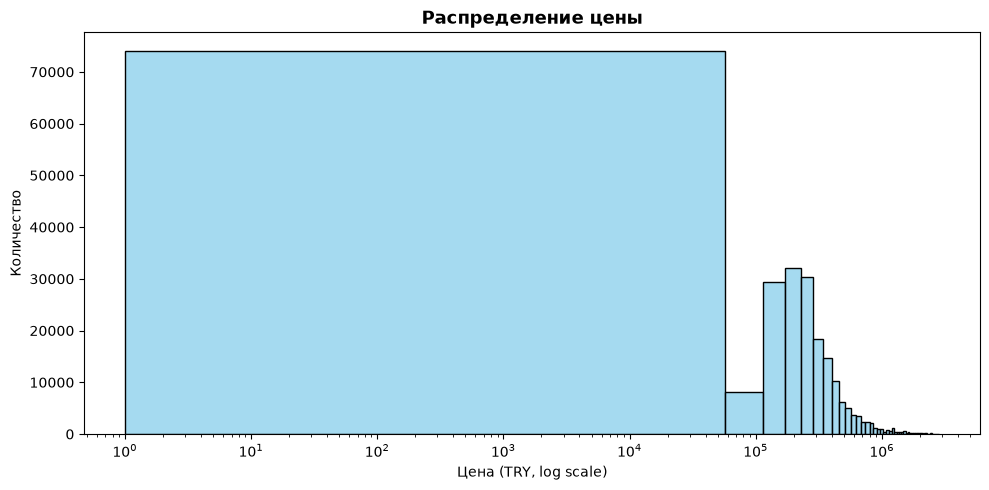

In [25]:
plt.figure(figsize=(10, 5))
sns.histplot(df_tr['price'].dropna(), bins=50, color='skyblue')
plt.xscale('log')
plt.title('Распределение цены', fontsize=13, fontweight='bold')
plt.xlabel('Цена (TRY, log scale)')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()
plt.close()

Распределение не нормальное, наблюдается ярко выраженный "длинный хвост". Большинство объектов сосредоточено в бюджетном и среднем сегменте, но есть супер-элитная недвижимость (цены до 2 млрд TRY). Требуется логарифмирование целевой переменной.

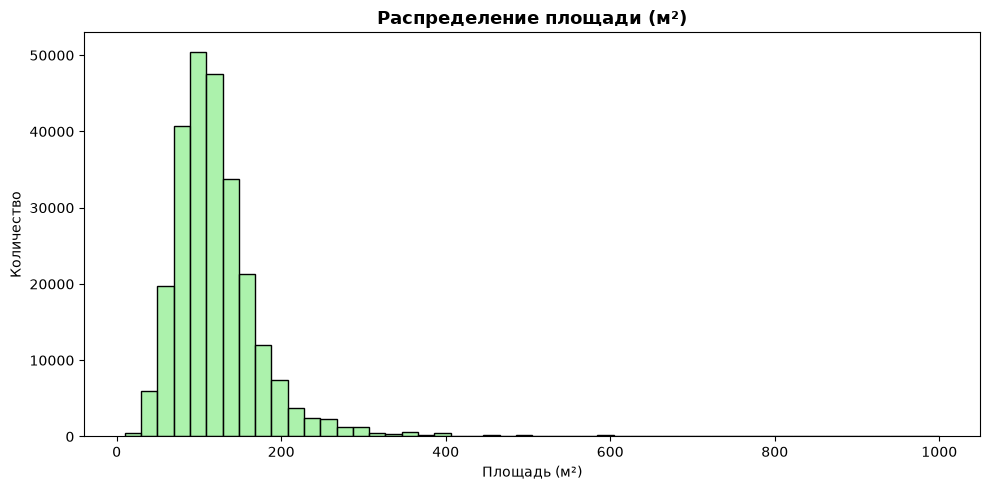

In [26]:
plt.figure(figsize=(10, 5))
sns.histplot(df_tr['size'].dropna(), bins=50, color='lightgreen')
plt.title('Распределение площади (м²)', fontsize=13, fontweight='bold')
plt.xlabel('Площадь (м²)')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()
plt.close()

Прослеживается четкий положительный тренд. Площадь - важный базовый предиктор. Однако при площади >200 м2 разброс цен становится очень широким: цена начинает зависеть от района и класса жилья, а не только от метров.

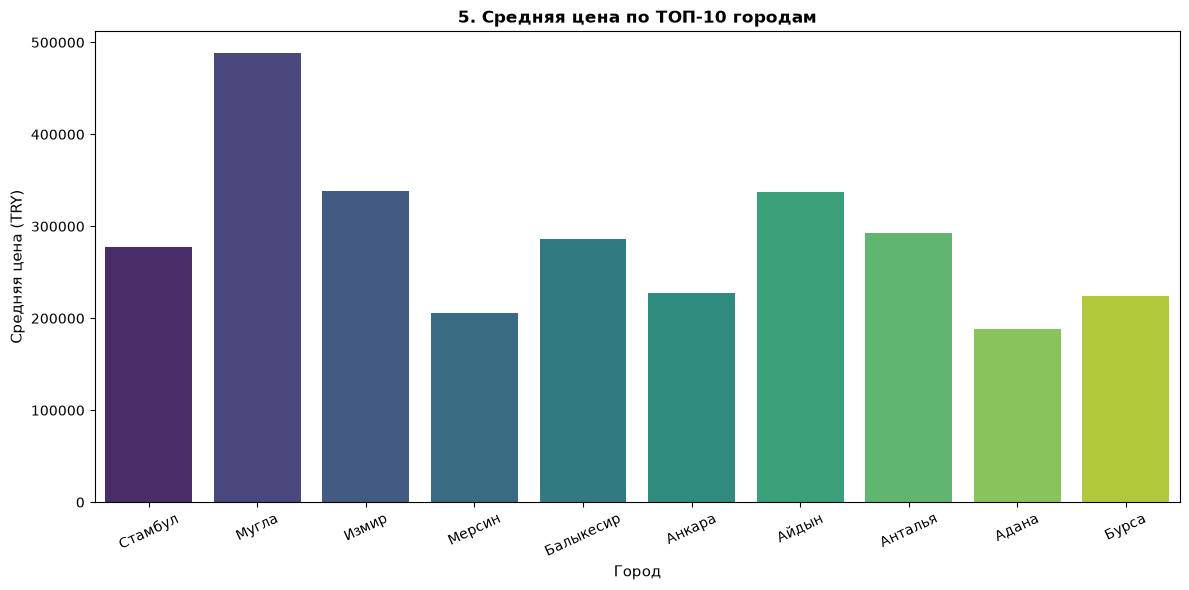

In [27]:
fig = plt.figure(figsize=(12, 6))
ax5 = plt.subplot(1, 1, 1)
top_cities = df_tr['city'].value_counts().head(10).index
df_top = df_tr[df_tr['city'].isin(top_cities)]
sns.barplot(x=df_top['city'], y=df_top['price'], errorbar=None, palette='viridis', ax=ax5)
ax5.set_title('5. Средняя цена по ТОП-10 городам', fontsize=12, fontweight='bold')
ax5.set_xlabel('Город', fontsize=11)
ax5.set_ylabel('Средняя цена (TRY)', fontsize=11)
ax5.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()


Мула доминирует по средним ценам на рынке турецкой недвижимости.
Стамбул, несмотря на большое количество предложений, имеет более низкие средние цены.
Региональные города показывают значительно меньшие ценовые показатели.

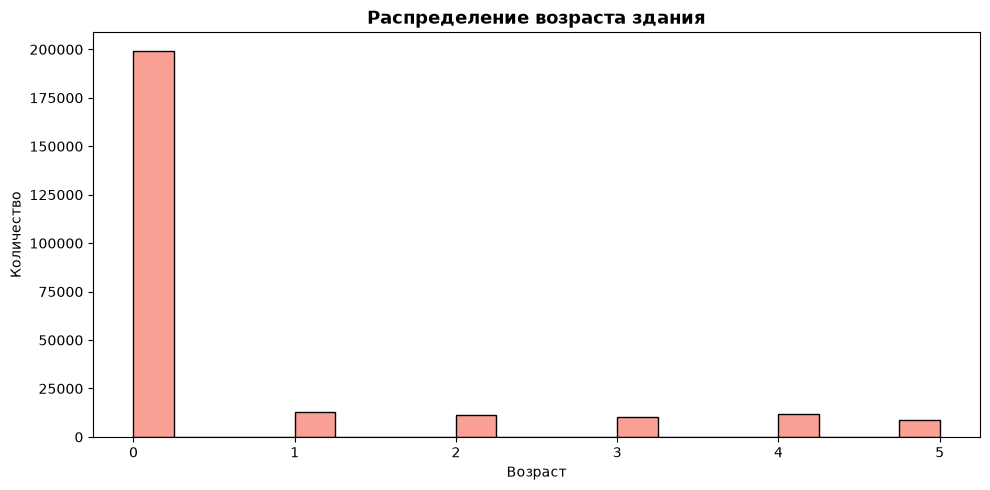

In [28]:
plt.figure(figsize=(10, 5))
sns.histplot(df_tr['building_age'].dropna(), bins=20, color='salmon')
plt.title('Распределение возраста здания', fontsize=13, fontweight='bold')
plt.xlabel('Возраст')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()
plt.close()

Огромный пик на значении 0 - это либо новостройки, либо пропуски, заполненные нулями. Признак лучше бинаризовать.

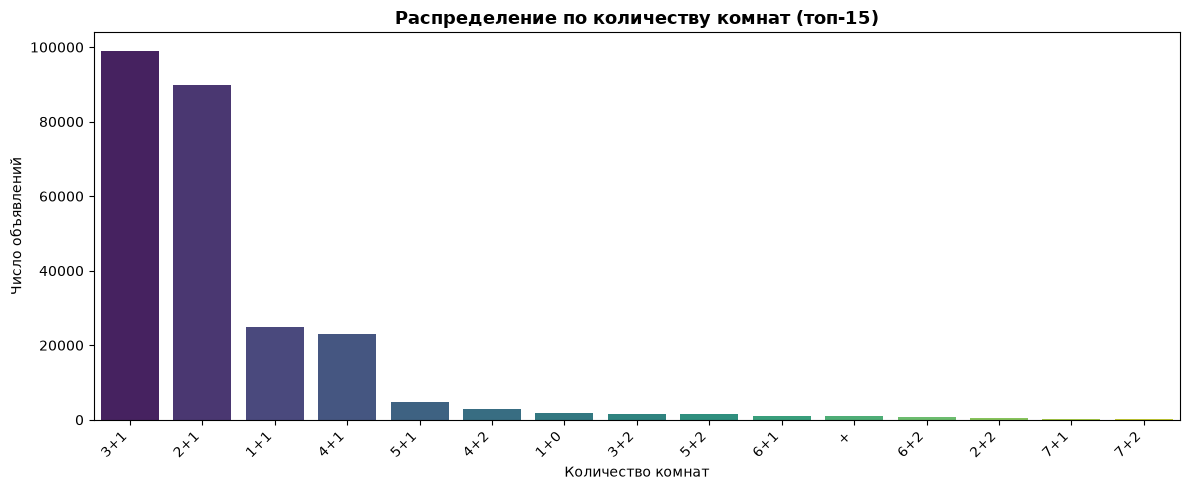

In [29]:
plt.figure(figsize=(12, 5))
# Берём только топ-15 самых частых значений комнат, чтобы не было кашы
top_rooms = df_tr['room_count'].value_counts().head(15).index
df_rooms = df_tr[df_tr['room_count'].isin(top_rooms)]

sns.countplot(data=df_rooms, x='room_count', order=top_rooms, palette='viridis')
plt.title('Распределение по количеству комнат (топ-15)', fontsize=13, fontweight='bold')
plt.xlabel('Количество комнат')
plt.ylabel('Число объявлений')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
plt.close()

Лидирует формат "3+1" (~40%), затем «2+1» и «1+0».

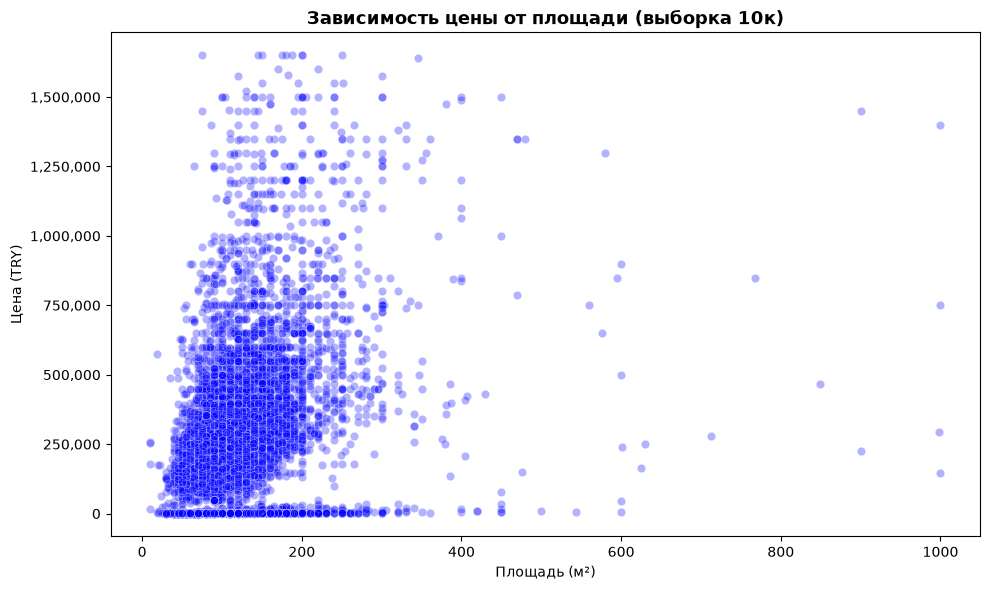

In [30]:
plt.figure(figsize=(10, 6))
# Берём выборку 10000 строк, чтобы не тормозило и не было сплошного пятна
sample_df = df_tr.sample(10000, random_state=42)
# Отсекаем экстремальные цены для читаемости
sample_df = sample_df[sample_df['price'] <= sample_df['price'].quantile(0.99)]

sns.scatterplot(data=sample_df, x='size', y='price', alpha=0.3, color='blue')
plt.title('Зависимость цены от площади (выборка 10к)', fontsize=13, fontweight='bold')
plt.xlabel('Площадь (м²)')
plt.ylabel('Цена (TRY)')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))
plt.tight_layout()
plt.show()
plt.close()

Положительная корреляция: чем больше площадь, тем выше цена. Разброс по вертикали из-за смешивания аренды и продажи.

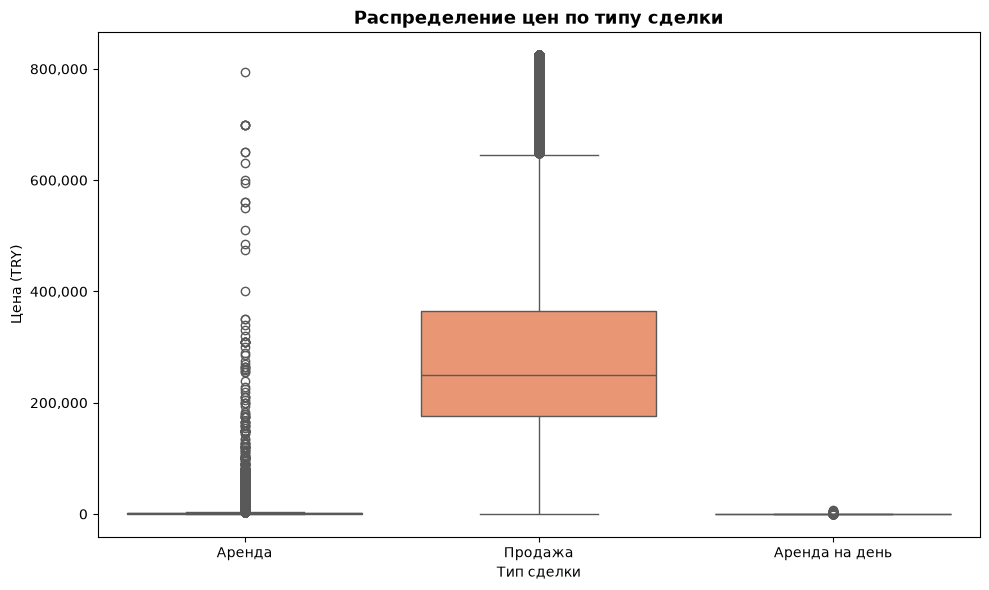

In [31]:
plt.figure(figsize=(10, 6))
price_limit = df_tr['price'].quantile(0.95)
df_box = df_tr[df_tr['price'] <= price_limit]

sns.boxplot(data=df_box, x='listing_type', y='price', palette='Set2')
plt.title('Распределение цен по типу сделки', fontsize=13, fontweight='bold')
plt.xlabel('Тип сделки')
plt.ylabel('Цена (TRY)')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))
plt.tight_layout()
plt.show()
plt.close()

Цены продажи и аренды отличаются на порядки. Медиана продажи -200k TRY, аренды -3k TRY. Ключевой признак для модели.

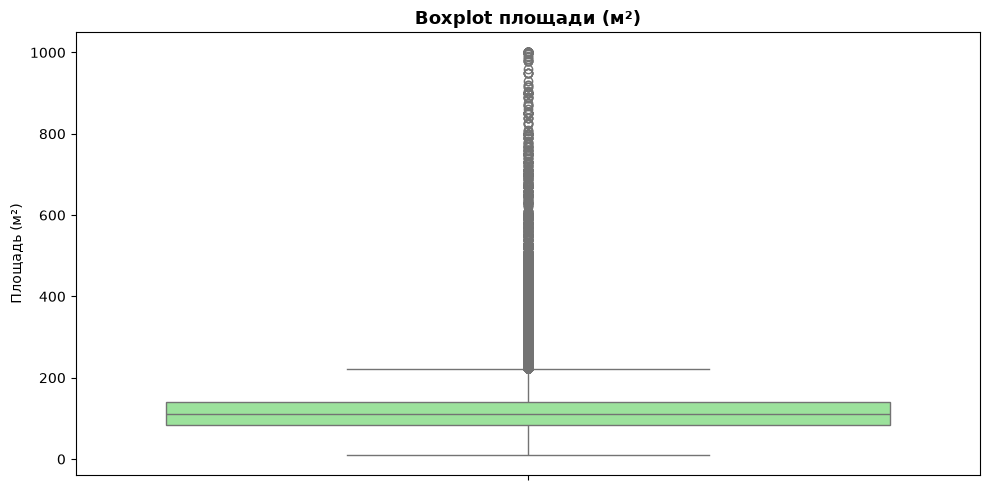

In [32]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_tr, y='size', color='lightgreen')
plt.title('Boxplot площади (м²)', fontsize=13, fontweight='bold')
plt.ylabel('Площадь (м²)')
plt.tight_layout()
plt.show()
plt.close()

Усы графика обрезаются на -250 м², но реальный максимум - 1000 м².
Наличие множества точек за пределами усов подтверждает сильные выбросы.
Нижняя граница (1 м2) - аномалия: квартира не может быть 1 м2.

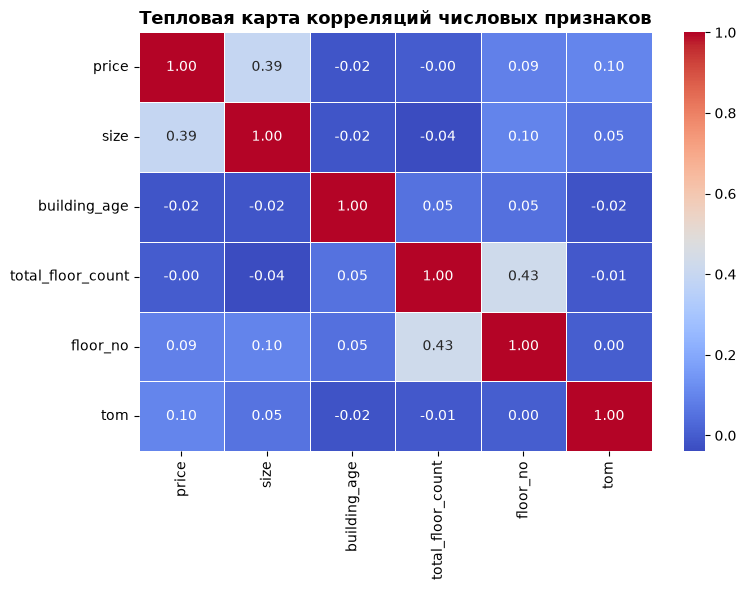

In [33]:
plt.figure(figsize=(8, 6))
cols_for_corr = ['price', 'size', 'building_age', 'total_floor_count', 'floor_no', 'tom']
corr_matrix = df_tr[cols_for_corr].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Тепловая карта корреляций числовых признаков', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
plt.close()

Цена сильнее всего коррелирует с площадью (size).

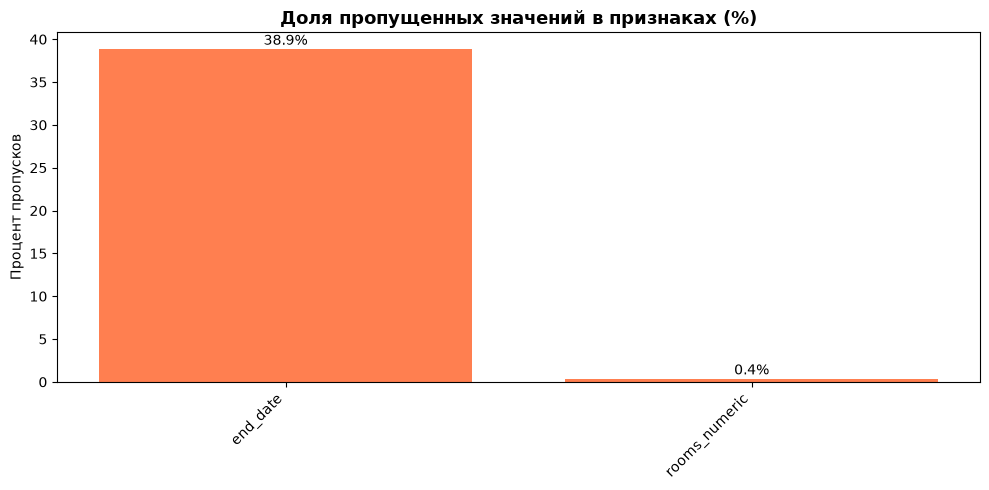

In [34]:
missing_data = df_tr.isnull().sum() / len(df_tr) * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
if len(missing_data) > 0:
    bars = plt.bar(missing_data.index, missing_data.values, color='coral')
    plt.title('Доля пропущенных значений в признаках (%)', fontsize=13, fontweight='bold')
    plt.ylabel('Процент пропусков')
    plt.xticks(rotation=45, ha='right')
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10)
else:
    plt.text(0.5, 0.5, 'Пропусков нет!', ha='center', va='center', fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()
plt.close()

Пропуски в end_date логичны (активные объявления).

Промежуточные выводы (Гипотезы)

На основе проведенного разведочного анализа (EDA) и построенных графиков можно выдвинуть следующие гипотезы о факторах, влияющих на стоимость недвижимости:

География (Город) — главный ценообразующий фактор.
Гипотеза: Локация влияет на цену сильнее, чем физические характеристики самого объекта. Недвижимость в Стамбуле и других ключевых регионах стоит кратно дороже.

Подтверждение: Barplot средней цены по ТОП-10 городам показывает колоссальный разрыв между лидерами рейтинга и остальными городами.
Площадь (size) — самый сильный числовой предиктор, но его влияние нелинейно.

Гипотеза: С ростом площади база цены растет, но для больших объектов разброс цен (дисперсия) становится огромным, так как в дело вступают факторы элитности и уникальности.

Подтверждение: Scatterplot (Площадь — Цена) демонстрирует положительный тренд, который "расширяется" в правой части графика. Тепловая карта корреляций подтверждает, что среди числовых признаков у size самая высокая корреляция с price.
Тип сделки (listing_type) фундаментально разделяет рынок.

Гипотеза: Аренда и продажа — это два разных рынка с разными ценовыми масштабами. Смешивание их в одну кучу без учета типа сделки исказит модель.
Подтверждение: Boxplot (Тип сделки — Цена) показывает, что медианы и межквартильные размахи для Продажа и Аренда находятся в совершенно разных весовых категориях.

Целевая переменная (цена) имеет экстремальный правосторонний перекос (длинный хвост).

Гипотеза: Прямое использование сырой цены для обучения (особенно линейных моделей и метрик вроде RMSE) приведет к тому, что модель будет подстраиваться только под сверхдорогие элитные объекты (выбросы).

Подтверждение: Описательная статистика (Асимметрия = 308.49, Эксцесс = 113727.01) и Гистограмма в логарифмическом масштабе. Вывод: перед обучением моделей цену необходимо логарифмировать (np.log1p).


### Предварительная обработка данных

### Обоснование стратегий обработки пропусков и аномалий

| Признак | Стратегия | Обоснование |
|---------|-----------|-------------|
| `furnished` | Удалена | 100% пропусков - неинформативна |
| `price ≤ 0` | Замена на NaN > удаление строки | Отрицательная цена — ошибка данных |
| `size < 10` или `> 1000` | Замена на NaN > заполнение медианой | Аномалии (1 м2 - ошибка, > 1000 м2 - ошибка) |
| `size` (пропуски 36%) | Групповая медиана по `(type, city)` | Цена зависит от города и типа - групповая медиана точнее |
| `building_age`, `total_floor_count`, `floor_no` (-7-9%) | Медиана | Распределение с модой в 0, медиана устойчивее |
| `heating_type` (7%) | Мода | Категориальный признак - заполняем самым частым |
| `district`, `neighborhood` (<0.01%) | `'Unknown'` | Мало пропусков, не критично |
| `price` (715 строк) | Удаление строк | Целевая переменная - без неё модель не обучится |
| Текстовые значения (`20 и более`, `Высокий первый этаж`) | Замена на числа | Для числовых моделей нужны числа |

In [35]:
if 'rooms_numeric' not in df_tr.columns:
    def parse_rooms(x):
        if pd.isna(x):
            return np.nan
        numbers = re.findall(r'\d+', str(x))
        if not numbers:
            return np.nan
        return sum(int(n) for n in numbers)
    df_tr['rooms_numeric'] = df_tr['room_count'].apply(parse_rooms)
    print("✅ rooms_numeric создан")
else:
    print("✅ rooms_numeric уже существует")

✅ rooms_numeric уже существует


In [36]:
#Цена за м2 (для анализа и как признак для регрессии)
df_tr['price_per_sqm'] = df_tr['price'] / df_tr['size']
print("✅ price_per_sqm создан")

✅ price_per_sqm создан


In [37]:
# Бинарный признак "новостройка" (возраст 0-5 лет)
df_tr['is_new_building'] = (df_tr['building_age'] <= 5).astype(int)
print("✅ is_new_building создан")

✅ is_new_building создан


In [38]:
# Бинарный признак "аренда/продажа" (для разделения рынков)
df_tr['is_rent'] = (df_tr['listing_type'] == 'Аренда').astype(int)
print("✅ is_rent создан")

✅ is_rent создан


In [39]:
# Логарифмирование цены (из гипотезы EDA: асимметрия = 308.49)
df_tr['log_price'] = np.log1p(df_tr['price'])
print(f"✅ log_price создан (асимметрия: {df_tr['log_price'].skew():.2f})")

✅ log_price создан (асимметрия: -0.88)


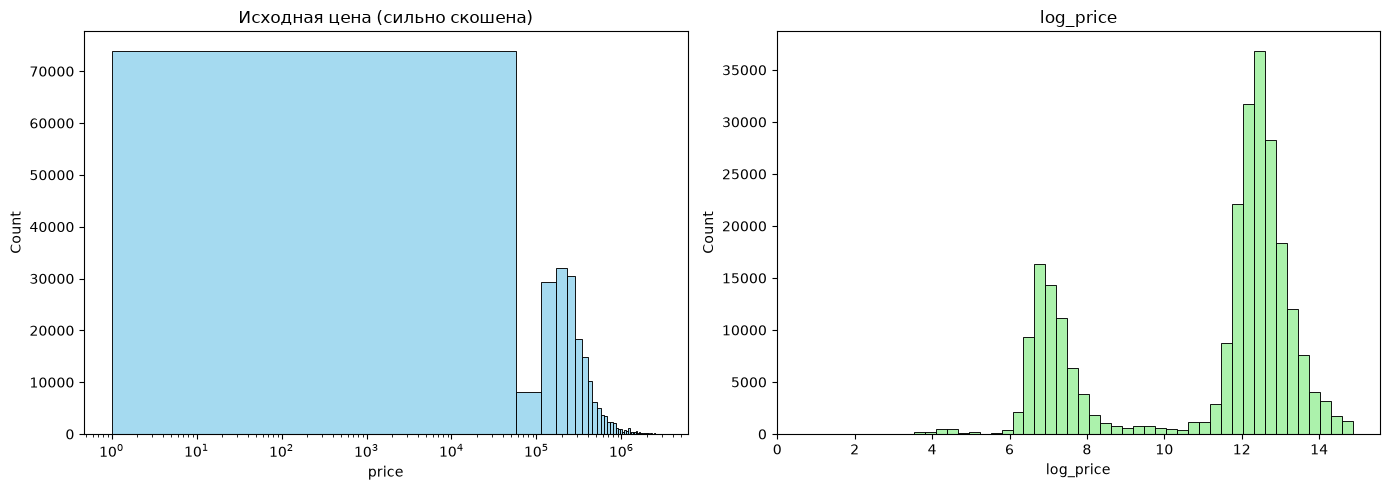

Асимметрия price:     3.14
Асимметрия log_price: -0.88


In [40]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_tr['price'], bins=50, ax=axes[0], color='skyblue')
axes[0].set_title('Исходная цена (сильно скошена)')
axes[0].set_xscale('log')

sns.histplot(df_tr['log_price'], bins=50, ax=axes[1], color='lightgreen')
axes[1].set_title('log_price')
plt.tight_layout()
plt.show()

print(f"Асимметрия price:     {df_tr['price'].skew():.2f}")
print(f"Асимметрия log_price: {df_tr['log_price'].skew():.2f}")

In [41]:
# Отношение этажа к общей этажности (показывает "высотность" квартиры)
df_tr['floor_ratio'] = df_tr['floor_no'] / df_tr['total_floor_count'].replace(0, 1)
print("✅ floor_ratio создан")

✅ floor_ratio создан


In [42]:
# Добавляем больше признаков
def create_advanced_features(df):
    df = df.copy()
    
    # Бинарные признаки
    df['is_penthouse'] = (df['floor_no'] == df['total_floor_count']).astype(int)
    df['is_ground_floor'] = (df['floor_no'] == 0).astype(int)
    df['is_high_floor'] = (df['floor_no'] >= 10).astype(int)
    
    # Взаимодействия
    df['size_per_room'] = df['size'] / df['rooms_numeric'].replace(0, 1)
    df['age_size_ratio'] = df['building_age'] / df['size']
    df['floor_size_ratio'] = df['floor_no'] / df['size']
    
    # Биннинг площади
    df['size_category'] = pd.cut(df['size'], bins=[0, 50, 100, 150, 200, 500, 10000], 
                                  labels=['very_small', 'small', 'medium', 'large', 'very_large', 'huge'])
    
    # Биннинг возраста
    df['age_category'] = pd.cut(df['building_age'], bins=[0, 5, 10, 20, 50, 100], 
                                 labels=['new', 'recent', 'medium', 'old', 'very_old'])
    
    return df

df_tr = create_advanced_features(df_tr)
print("✅ Дополнительные признаки созданы")

✅ Дополнительные признаки созданы


In [43]:
# Группировка редких категорий комнат в "Другое"
room_counts = df_tr['room_count'].value_counts()
rare_rooms = room_counts[room_counts < 500].index
df_tr['room_grouped'] = df_tr['room_count'].replace(rare_rooms, 'Другое')
print(f"✅ room_grouped создан (редких категорий заменено: {len(rare_rooms)})")

✅ room_grouped создан (редких категорий заменено: 19)


In [44]:
print(f"\nИтоговая размерность: {df_tr.shape}")


Итоговая размерность: (253886, 33)


### Проверка мультиколлинеарности (VIF)

In [45]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
numeric_cols = ['size', 'building_age', 'total_floor_count', 'floor_no', 'rooms_numeric']
X_vif = df_tr[numeric_cols].dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]
print("Проверка мультиколлинеарности (VIF)")
print(vif_data.sort_values('VIF', ascending=False))

Проверка мультиколлинеарности (VIF)
             feature        VIF
4      rooms_numeric  14.289303
0               size  11.067850
2  total_floor_count   4.179049
3           floor_no   3.257824
1       building_age   1.198251


In [46]:
print("Кодирование категориальных признаков")

# Номинальные признаки (без порядка)
nominal_cols = ['city', 'heating_type', 'type', 'sub_type']

# Группировка редких городов (топ-15, остальные - Другое)
top_cities = df_tr['city'].value_counts().head(15).index
df_tr['city_grouped'] = df_tr['city'].apply(lambda x: x if x in top_cities else 'Другоe')
print(f"✅ city_grouped создан (топ-15 городов, остальные - Другое)")


df_encoded = pd.get_dummies(
    df_tr, 
    columns=nominal_cols + ['city_grouped', 'room_grouped'],
    drop_first=False, 
    dtype=int
)

print(f"Новая размерность: {df_encoded.shape}")
print(f"Новые столбцы: {len(df_encoded.columns) - len(df_tr.columns)}")

Кодирование категориальных признаков
✅ city_grouped создан (топ-15 городов, остальные - Другое)
Новая размерность: (253886, 168)
Новые столбцы: 134


# Масштабирование признаков 

In [47]:
from sklearn.preprocessing import StandardScaler, RobustScaler

Обоснование выбора RobustScaler:
 - StandardScaler чувствителен к выбросам (а у нас цена с длинным хвостом)
 - MinMaxScaler тоже чувствителен к выбросам
 - RobustScaler использует медиану и IQR - устойчив к выбросам
 - Для деревьев (RandomForest, XGBoost) масштабирование не нужно,
   но для линейных моделей (Ridge, Lasso) - обязательно

In [48]:
if 'log_price' not in df_encoded.columns:
    df_encoded['log_price'] = np.log1p(df_encoded['price'])
    print("log_price создан")

columns_to_drop = [
    'log_price',   
    'price',           
    'price_per_sqm',   
    'id', 'start_date', 'end_date', 'tom', 'price_currency'
]
columns_to_drop = [c for c in columns_to_drop if c in df_encoded.columns]

# 3. Признаки для масштабирования (только из тех, что реально числовые и не one-hot)
features_to_scale = ['size', 'total_floor_count',
                     'floor_no', 'rooms_numeric', 'floor_ratio']
features_to_scale = [c for c in features_to_scale if c in df_encoded.columns]

print("Удаляем:", columns_to_drop)
print("Масштабируем:", features_to_scale)

Удаляем: ['log_price', 'price', 'price_per_sqm', 'id', 'start_date', 'end_date', 'tom', 'price_currency']
Масштабируем: ['size', 'total_floor_count', 'floor_no', 'rooms_numeric', 'floor_ratio']


In [49]:
# 2.6 Разбиение данных на train/validation/test
from sklearn.model_selection import train_test_split

# Проверяем и удаляем строки с NaN в целевой переменной
print(f"Пропусков в log_price до очистки: {df_encoded['log_price'].isna().sum()}")

# Удаляем строки где log_price = NaN
df_encoded = df_encoded.dropna(subset=['log_price'])

print(f"Пропусков в log_price после очистки: {df_encoded['log_price'].isna().sum()}")
print(f"Размер датасета после очистки: {df_encoded.shape}")

# Целевая переменная
target = 'log_price'

columns_to_drop = [
    target,
    'price',
    'price_per_sqm',
    'id',
    'start_date',
    'end_date',
    'tom',
    'price_currency',
    # ВАЖНО: удаляем строковые колонки, которые не были закодированы
    'listing_type',
    'room_count',
    'district',
    'neighborhood',
]

# Оставляем только те столбцы, которые реально есть в df_encoded
columns_to_drop = [col for col in columns_to_drop if col in df_encoded.columns]

print("Удаляемые столбцы:", columns_to_drop)

# Разделяем признаки и целевую переменную
X = df_encoded.drop(columns=columns_to_drop)
y = df_encoded[target]

print(f"Размер X: {X.shape}")
print(f"Размер y: {y.shape}")

# Проверка: строковых колонок быть не должно
object_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()
if len(object_cols) > 0:
    print(f"❌ Остались строковые колонки: {object_cols}")
else:
    print("✅ Все колонки числовые")

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15/0.85, random_state=42
)

print(f"\nTrain:      {X_train.shape[0]:>7} объектов ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation: {X_val.shape[0]:>7} объектов ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test:       {X_test.shape[0]:>7} объектов ({X_test.shape[0]/len(X)*100:.1f}%)")

Пропусков в log_price до очистки: 0
Пропусков в log_price после очистки: 0
Размер датасета после очистки: (253886, 168)
Удаляемые столбцы: ['log_price', 'price', 'price_per_sqm', 'id', 'start_date', 'end_date', 'tom', 'price_currency', 'listing_type', 'room_count', 'district', 'neighborhood']
Размер X: (253886, 156)
Размер y: (253886,)
✅ Все колонки числовые

Train:       177720 объектов (70.0%)
Validation:   38083 объектов (15.0%)
Test:         38083 объектов (15.0%)


In [50]:
scaler = RobustScaler()

X_train_scaled = X_train.copy()
X_val_scaled   = X_val.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[features_to_scale] = scaler.fit_transform(X_train[features_to_scale])
X_val_scaled[features_to_scale]   = scaler.transform(X_val[features_to_scale])
X_test_scaled[features_to_scale]  = scaler.transform(X_test[features_to_scale])

print(" Масштабирование выполнено корректно")
print("\nСтатистики train после масштабирования:")
print(X_train_scaled[features_to_scale].describe().round(2))

 Масштабирование выполнено корректно

Статистики train после масштабирования:
            size  total_floor_count   floor_no  rooms_numeric  floor_ratio
count  177720.00          177720.00  177720.00      177051.00    177720.00
mean        0.21               0.37       0.20          -0.35         0.09
std         1.13               1.36       1.33           1.08         1.01
min        -1.82              -1.50      -1.00          -3.00        -1.17
25%        -0.45              -0.50      -0.50          -1.00        -0.58
50%         0.00               0.00       0.00           0.00         0.00
75%         0.55               0.50       0.50           0.00         0.42
max        16.18               8.00       8.50          10.00        32.08


In [51]:
import joblib

# Данные для деревьев
X_train.to_csv('X_train.csv', index=False)
X_val.to_csv('X_val.csv', index=False)
X_test.to_csv('X_test.csv', index=False)

# Данные для линейных моделей
X_train_scaled.to_csv('X_train_scaled.csv', index=False)
X_val_scaled.to_csv('X_val_scaled.csv', index=False)
X_test_scaled.to_csv('X_test_scaled.csv', index=False)

# Целевые
y_train.to_csv('y_train.csv', index=False)
y_val.to_csv('y_val.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

# Скалер - обязательно для приложения
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(features_to_scale, 'features_to_scale.pkl')
joblib.dump(list(X_train.columns), 'feature_columns.pkl')

['feature_columns.pkl']

## Этап 3. Построение модели регрессии

первым делом нужно импортировать библиотеки, которые нам понадобятся для работы

In [52]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
from scipy.stats import randint, uniform
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings('ignore')

print("✅ Библиотеки импортированы")

✅ Библиотеки импортированы


In [53]:
# Загрузка данных
X_train = pd.read_csv('X_train.csv')
X_val = pd.read_csv('X_val.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv')
y_val = pd.read_csv('y_val.csv')
y_test = pd.read_csv('y_test.csv')

scaler = joblib.load('scaler.pkl')
features_to_scale = joblib.load('features_to_scale.pkl')
feature_columns = joblib.load('feature_columns.pkl')

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
print(f"Целевая переменная: log_price")

Train: (177720, 156), Val: (38083, 156), Test: (38083, 156)
Целевая переменная: log_price


In [54]:
# Проверяем и удаляем NaN в признаках и целевой переменной
print(f"NaN в X_train до очистки: {X_train.isnull().sum().sum()}")
print(f"NaN в y_train до очистки: {y_train.isnull().sum()}")

# Удаляем строки с NaN в признаках
mask_train = X_train.notnull().all(axis=1)
mask_val   = X_val.notnull().all(axis=1)
mask_test  = X_test.notnull().all(axis=1)

X_train = X_train[mask_train].copy()
y_train = y_train[mask_train].copy()

X_val = X_val[mask_val].copy()
y_val = y_val[mask_val].copy()

X_test = X_test[mask_test].copy()
y_test = y_test[mask_test].copy()

print(f"\nПосле очистки:")
print(f"Train:      {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Test:       {X_test.shape}")

# Повторное масштабирование на чистых данных
X_train_scaled = X_train.copy()
X_val_scaled   = X_val.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[features_to_scale] = scaler.fit_transform(X_train[features_to_scale])
X_val_scaled[features_to_scale]   = scaler.transform(X_val[features_to_scale])
X_test_scaled[features_to_scale]  = scaler.transform(X_test[features_to_scale])

print("✅ Данные очищены и масштабированы")

NaN в X_train до очистки: 140622
NaN в y_train до очистки: log_price    0
dtype: int64

После очистки:
Train:      (38378, 156)
Validation: (8206, 156)
Test:       (8237, 156)
✅ Данные очищены и масштабированы


In [55]:
def calculate_metrics(y_true_log, y_pred_log, model_name=""):
    """Расчет метрик в log и в исходных TRY"""
    # Метрики в log-пространстве
    mae_log  = mean_absolute_error(y_true_log, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    mape_log = mean_absolute_percentage_error(y_true_log, y_pred_log) * 100
    r2_log   = r2_score(y_true_log, y_pred_log)
    
    # Переводим в TRY
    y_true_try = np.expm1(y_true_log)
    y_pred_try = np.expm1(y_pred_log)
    
    # Метрики в TRY
    mae_try  = mean_absolute_error(y_true_try, y_pred_try)
    rmse_try = np.sqrt(mean_squared_error(y_true_try, y_pred_try))
    mape_try = mean_absolute_percentage_error(y_true_try, y_pred_try) * 100
    r2_try   = r2_score(y_true_try, y_pred_try)
    
    return {
        'Модель': model_name,
        'MAE_log':  round(mae_log, 4),
        'RMSE_log': round(rmse_log, 4),
        'MAPE_log': round(mape_log, 2),
        'R²_log':   round(r2_log, 4),
        'MAE_TRY':  round(mae_try, 2),
        'RMSE_TRY': round(rmse_try, 2),
        'MAPE_TRY': round(mape_try, 2),
        'R²_TRY':   round(r2_try, 4),
    }

def print_metrics(metrics_dict):
    """Красивый вывод метрик"""
    print(f"\n{metrics_dict['Модель']}:")
    print(f"  В log-пространстве:")
    print(f"    MAE:  {metrics_dict['MAE_log']:.4f}")
    print(f"    RMSE: {metrics_dict['RMSE_log']:.4f}")
    print(f"    MAPE: {metrics_dict['MAPE_log']:.2f}%")
    print(f"    R²:   {metrics_dict['R²_log']:.4f}")
    print(f"  В TRY (исходные единицы):")
    print(f"    MAE:  {metrics_dict['MAE_TRY']:,.2f} TRY")
    print(f"    RMSE: {metrics_dict['RMSE_TRY']:,.2f} TRY")
    print(f"    MAPE: {metrics_dict['MAPE_TRY']:.2f}%")
    print(f"    R²:   {metrics_dict['R²_TRY']:.4f}")

print("✅ Функции метрик созданы")

✅ Функции метрик созданы


In [57]:
# 1. Оставляем только числовые столбцы в X_train, X_val, X_test
numeric_cols = X_train.select_dtypes(include=['number']).columns

X_train = X_train[numeric_cols]
X_val = X_val[numeric_cols]
X_test = X_test[numeric_cols]

print(f"✅ Оставлены только числовые признаки. Количество: {len(numeric_cols)}")
print(f"   Примеры столбцов: {list(numeric_cols[:5])}...")

# 2. Обновляем список признаков для масштабирования (оставляем только те, что есть в X_train)
features_to_scale = [c for c in features_to_scale if c in X_train.columns]

# 3. Повторно масштабируем данные (так как состав столбцов изменился)
scaler = RobustScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

X_train_scaled[features_to_scale] = scaler.fit_transform(X_train[features_to_scale])
X_val_scaled[features_to_scale] = scaler.transform(X_val[features_to_scale])
X_test_scaled[features_to_scale] = scaler.transform(X_test[features_to_scale])

print("✅ Данные очищены от строк и масштабированы. Можно обучать модели!\n")
models = {}
results = []

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 1. Ridge (линейная) — на масштабированных данных
print("1. Ridge Regression...")
ridge = Ridge(alpha=1.0, random_state=RANDOM_STATE)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_val_scaled)
metrics_ridge = calculate_metrics(y_val, y_pred_ridge, "Ridge")
results.append(metrics_ridge)
models['Ridge'] = ridge
print_metrics(metrics_ridge)

# 2. Decision Tree (дерево) — на исходных данных
print("\n2. Decision Tree...")
dt = DecisionTreeRegressor(random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_val)
metrics_dt = calculate_metrics(y_val, y_pred_dt, "Decision Tree")
results.append(metrics_dt)
models['Decision Tree'] = dt
print_metrics(metrics_dt)

# 3. Random Forest (бэггинг) — на исходных данных
print("\n3. Random Forest...")
rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_val)
metrics_rf = calculate_metrics(y_val, y_pred_rf, "Random Forest")
results.append(metrics_rf)
models['Random Forest'] = rf
print_metrics(metrics_rf)

# 4. Gradient Boosting (бустинг) — на исходных данных
print("\n4. Gradient Boosting...")
gb = GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_val)
metrics_gb = calculate_metrics(y_val, y_pred_gb, "Gradient Boosting")
results.append(metrics_gb)
models['Gradient Boosting'] = gb
print_metrics(metrics_gb)

print("\n✅ Базовые модели успешно обучены")

✅ Оставлены только числовые признаки. Количество: 154
   Примеры столбцов: ['building_age', 'total_floor_count', 'floor_no', 'size', 'rooms_numeric']...
✅ Данные очищены от строк и масштабированы. Можно обучать модели!

1. Ridge Regression...

Ridge:
  В log-пространстве:
    MAE:  0.5437
    RMSE: 1.0402
    MAPE: 6.90%
    R²:   0.8531
  В TRY (исходные единицы):
    MAE:  100,791.95 TRY
    RMSE: 237,309.37 TRY
    MAPE: 1658.31%
    R²:   0.4655

2. Decision Tree...

Decision Tree:
  В log-пространстве:
    MAE:  0.3325
    RMSE: 0.8118
    MAPE: 3.67%
    R²:   0.9105
  В TRY (исходные единицы):
    MAE:  73,303.53 TRY
    RMSE: 196,928.30 TRY
    MAPE: 1197.44%
    R²:   0.6319

3. Random Forest...

Random Forest:
  В log-пространстве:
    MAE:  0.2974
    RMSE: 0.6521
    MAPE: 3.33%
    R²:   0.9423
  В TRY (исходные единицы):
    MAE:  64,553.59 TRY
    RMSE: 161,991.10 TRY
    MAPE: 684.82%
    R²:   0.7509

4. Gradient Boosting...

Gradient Boosting:
  В log-пространстве:
  

In [58]:
# XGBoost
print("5. XGBoost...")
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_val)
metrics_xgb = calculate_metrics(y_val, y_pred_xgb, "XGBoost")
results.append(metrics_xgb)
models['XGBoost'] = xgb
print_metrics(metrics_xgb)

# LightGBM
print("\n6. LightGBM...")
lgbm = LGBMRegressor(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgbm.fit(X_train, y_train)
y_pred_lgbm = lgbm.predict(X_val)
metrics_lgbm = calculate_metrics(y_val, y_pred_lgbm, "LightGBM")
results.append(metrics_lgbm)
models['LightGBM'] = lgbm
print_metrics(metrics_lgbm)

5. XGBoost...

XGBoost:
  В log-пространстве:
    MAE:  0.3120
    RMSE: 0.6050
    MAPE: 3.43%
    R²:   0.9503
  В TRY (исходные единицы):
    MAE:  69,678.13 TRY
    RMSE: 164,480.57 TRY
    MAPE: 343.89%
    R²:   0.7432

6. LightGBM...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001255 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1324
[LightGBM] [Info] Number of data points in the train set: 38378, number of used features: 123
[LightGBM] [Info] Start training from score 10.746957
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

In [59]:
# Обновляем сводную таблицу с новыми моделями
results_df = pd.DataFrame(results)
all_results = pd.concat([results_df], ignore_index=True)
all_results_sorted = all_results.sort_values('R²_TRY', ascending=False)

print("\n" + "="*80)
print(" ОБНОВЛЁННАЯ СВОДНАЯ ТАБЛИЦА ВСЕХ МОДЕЛЕЙ")
print("="*80)
print(all_results_sorted.to_string(index=False))
print("="*80)

# Топ-5 моделей
print("\n🏆 ТОП-5 МОДЕЛЕЙ ПО R²:")
print(all_results_sorted.head(5)[['Модель', 'R²_TRY', 'MAPE_TRY']].to_string(index=False))

# Проверяем, изменилась ли лучшая модель
new_best_name = all_results_sorted.iloc[0]['Модель']
print(f"\n📌 Лучшая модель: {new_best_name}")
print(f"   R²: {all_results_sorted.iloc[0]['R²_TRY']:.4f}")
print(f"   MAPE: {all_results_sorted.iloc[0]['MAPE_TRY']:.2f}%")


 ОБНОВЛЁННАЯ СВОДНАЯ ТАБЛИЦА ВСЕХ МОДЕЛЕЙ
           Модель  MAE_log  RMSE_log  MAPE_log  R²_log   MAE_TRY  RMSE_TRY  MAPE_TRY  R²_TRY
    Random Forest   0.2974    0.6521      3.33  0.9423  64553.59 161991.10    684.82  0.7509
          XGBoost   0.3120    0.6050      3.43  0.9503  69678.13 164480.57    343.89  0.7432
         LightGBM   0.3523    0.6450      3.95  0.9435  78534.63 181083.82    392.71  0.6887
    Decision Tree   0.3325    0.8118      3.67  0.9105  73303.53 196928.30   1197.44  0.6319
Gradient Boosting   0.4445    0.8619      5.36  0.8991  90571.81 205421.70    985.02  0.5995
            Ridge   0.5437    1.0402      6.90  0.8531 100791.95 237309.37   1658.31  0.4655

🏆 ТОП-5 МОДЕЛЕЙ ПО R²:
           Модель  R²_TRY  MAPE_TRY
    Random Forest  0.7509    684.82
          XGBoost  0.7432    343.89
         LightGBM  0.6887    392.71
    Decision Tree  0.6319   1197.44
Gradient Boosting  0.5995    985.02

📌 Лучшая модель: Random Forest
   R²: 0.7509
   MAPE: 684.82%


In [60]:
print("🔧 Подбор гиперпараметров с кросс-валидацией (cv=3)\n")

# 1. Ridge — подбор alpha
print("1. Ridge — подбор alpha...")
ridge_params = {'alpha': [0.1, 1, 10, 100, 1000]}
ridge_cv = GridSearchCV(Ridge(random_state=RANDOM_STATE), ridge_params,
                        cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
ridge_cv.fit(X_train_scaled, y_train)
print(f"   Лучшие параметры: {ridge_cv.best_params_}")
print(f"   Лучший MAE (log): {-ridge_cv.best_score_:.4f}\n")

# 2. Decision Tree — подбор max_depth
print("2. Decision Tree — подбор max_depth...")
tree_params = {'max_depth': [5, 10, 15, 20, None],
               'min_samples_split': [2, 5, 10]}
tree_cv = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE), tree_params,
                       cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
tree_cv.fit(X_train, y_train)
print(f"   Лучшие параметры: {tree_cv.best_params_}")
print(f"   Лучший MAE (log): {-tree_cv.best_score_:.4f}\n")

# 3. Random Forest — подбор n_estimators и max_depth
print("3. Random Forest — подбор n_estimators и max_depth...")
rf_params = {'n_estimators': [50, 100, 200],
             'max_depth': [10, 20, None]}
rf_cv = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                     rf_params, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
rf_cv.fit(X_train, y_train)
print(f"   Лучшие параметры: {rf_cv.best_params_}")
print(f"   Лучший MAE (log): {-rf_cv.best_score_:.4f}\n")

# 4. Gradient Boosting — подбор n_estimators и learning_rate
print("4. Gradient Boosting — подбор n_estimators и learning_rate...")
gb_params = {'n_estimators': [100, 200, 300],
             'learning_rate': [0.01, 0.05, 0.1]}
gb_cv = GridSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE),
                     gb_params, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
gb_cv.fit(X_train, y_train)
print(f"   Лучшие параметры: {gb_cv.best_params_}")
print(f"   Лучший MAE (log): {-gb_cv.best_score_:.4f}\n")

print("✅ Гиперпараметры подобраны")

🔧 Подбор гиперпараметров с кросс-валидацией (cv=3)

1. Ridge — подбор alpha...
   Лучшие параметры: {'alpha': 10}
   Лучший MAE (log): 0.5513

2. Decision Tree — подбор max_depth...
   Лучшие параметры: {'max_depth': 20, 'min_samples_split': 2}
   Лучший MAE (log): 0.3685

3. Random Forest — подбор n_estimators и max_depth...
   Лучшие параметры: {'max_depth': None, 'n_estimators': 200}
   Лучший MAE (log): 0.3200

4. Gradient Boosting — подбор n_estimators и learning_rate...
   Лучшие параметры: {'learning_rate': 0.1, 'n_estimators': 300}
   Лучший MAE (log): 0.4341

✅ Гиперпараметры подобраны


In [61]:
final_models = {}
final_results = []

# 1. Ridge с лучшим alpha
print("1. Final Ridge...")
ridge_best = Ridge(**ridge_cv.best_params_, random_state=RANDOM_STATE)
ridge_best.fit(X_train_scaled, y_train)
y_pred_rb = ridge_best.predict(X_val_scaled)
metrics_rb = calculate_metrics(y_val, y_pred_rb, "Ridge (tuned)")
final_results.append(metrics_rb)
final_models['Ridge (tuned)'] = ridge_best
print_metrics(metrics_rb)

# 2. Decision Tree с лучшими параметрами
print("\n2. Final Decision Tree...")
dt_best = DecisionTreeRegressor(**tree_cv.best_params_, random_state=RANDOM_STATE)
dt_best.fit(X_train, y_train)
y_pred_db = dt_best.predict(X_val)
metrics_db = calculate_metrics(y_val, y_pred_db, "Decision Tree (tuned)")
final_results.append(metrics_db)
final_models['Decision Tree (tuned)'] = dt_best
print_metrics(metrics_db)

# 3. Random Forest с лучшими параметрами
print("\n3. Final Random Forest...")
rf_best = RandomForestRegressor(**rf_cv.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
rf_best.fit(X_train, y_train)
y_pred_rfb = rf_best.predict(X_val)
metrics_rfb = calculate_metrics(y_val, y_pred_rfb, "Random Forest (tuned)")
final_results.append(metrics_rfb)
final_models['Random Forest (tuned)'] = rf_best
print_metrics(metrics_rfb)

# 4. Gradient Boosting с лучшими параметрами
print("\n4. Final Gradient Boosting...")
gb_best = GradientBoostingRegressor(**gb_cv.best_params_, random_state=RANDOM_STATE)
gb_best.fit(X_train, y_train)
y_pred_gbb = gb_best.predict(X_val)
metrics_gbb = calculate_metrics(y_val, y_pred_gbb, "Gradient Boosting (tuned)")
final_results.append(metrics_gbb)
final_models['Gradient Boosting (tuned)'] = gb_best
print_metrics(metrics_gbb)

print("\n✅ Финальные модели обучены")

1. Final Ridge...

Ridge (tuned):
  В log-пространстве:
    MAE:  0.5425
    RMSE: 1.0396
    MAPE: 6.90%
    R²:   0.8533
  В TRY (исходные единицы):
    MAE:  100,573.63 TRY
    RMSE: 234,805.53 TRY
    MAPE: 1604.96%
    R²:   0.4767

2. Final Decision Tree...

Decision Tree (tuned):
  В log-пространстве:
    MAE:  0.3441
    RMSE: 0.7959
    MAPE: 3.77%
    R²:   0.9140
  В TRY (исходные единицы):
    MAE:  75,730.07 TRY
    RMSE: 187,345.00 TRY
    MAPE: 1260.34%
    R²:   0.6668

3. Final Random Forest...

Random Forest (tuned):
  В log-пространстве:
    MAE:  0.2953
    RMSE: 0.6471
    MAPE: 3.31%
    R²:   0.9432
  В TRY (исходные единицы):
    MAE:  64,222.88 TRY
    RMSE: 161,164.84 TRY
    MAPE: 663.94%
    R²:   0.7535

4. Final Gradient Boosting...

Gradient Boosting (tuned):
  В log-пространстве:
    MAE:  0.4211
    RMSE: 0.8102
    MAPE: 5.00%
    R²:   0.9109
  В TRY (исходные единицы):
    MAE:  87,736.33 TRY
    RMSE: 213,069.57 TRY
    MAPE: 717.45%
    R²:   0.569

In [159]:
# XGBoost
print("5. XGBoost...")
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_val)
metrics_xgb = calculate_metrics(y_val, y_pred_xgb, "XGBoost")
results.append(metrics_xgb)
models['XGBoost'] = xgb
print_metrics(metrics_xgb)

# LightGBM
print("\n6. LightGBM...")
lgbm = LGBMRegressor(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgbm.fit(X_train, y_train)
y_pred_lgbm = lgbm.predict(X_val)
metrics_lgbm = calculate_metrics(y_val, y_pred_lgbm, "LightGBM")
results.append(metrics_lgbm)
models['LightGBM'] = lgbm
print_metrics(metrics_lgbm)

print("\n✅ Все модели обучены")

5. XGBoost...

XGBoost:
  В log-пространстве:
    MAE:  0.2740
    RMSE: 0.4245
    MAPE: 2.64%
    R²:   0.9716
  В TRY (исходные единицы):
    MAE:  102,534.02 TRY
    RMSE: 947,589.28 TRY
    MAPE: 45.85%
    R²:   0.3065

6. LightGBM...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003350 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 668
[LightGBM] [Info] Number of data points in the train set: 143150, number of used features: 129
[LightGBM] [Info] Start training from score 11.109312
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

LightGBM:
  В log-пространстве:
    MAE:  0.3008
    RMSE: 0.4533
    MAPE: 2.89%
    R²:   0.9676
  В TRY (исходные единицы):
    MAE:  113,725.84 TRY
    RMSE: 1,006,793.52 TRY
    MAPE: 49.68%

In [62]:
# Объединяем базовые и финальные результаты
all_results = pd.concat([results_df, pd.DataFrame(final_results)], ignore_index=True)
all_results_sorted = all_results.sort_values('R²_TRY', ascending=False)

print("\n" + "="*80)
print("📊 СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ (базовые + tuned)")
print("="*80)
print(all_results_sorted.to_string(index=False))
print("="*80)

# Топ-5 моделей по R²
print("\n🏆 ТОП-5 МОДЕЛЕЙ ПО R²:")
print(all_results_sorted.head(5)[['Модель', 'R²_TRY', 'MAPE_TRY']].to_string(index=False))


📊 СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ (базовые + tuned)
                   Модель  MAE_log  RMSE_log  MAPE_log  R²_log   MAE_TRY  RMSE_TRY  MAPE_TRY  R²_TRY
    Random Forest (tuned)   0.2953    0.6471      3.31  0.9432  64222.88 161164.84    663.94  0.7535
            Random Forest   0.2974    0.6521      3.33  0.9423  64553.59 161991.10    684.82  0.7509
                  XGBoost   0.3120    0.6050      3.43  0.9503  69678.13 164480.57    343.89  0.7432
                 LightGBM   0.3523    0.6450      3.95  0.9435  78534.63 181083.82    392.71  0.6887
    Decision Tree (tuned)   0.3441    0.7959      3.77  0.9140  75730.07 187345.00   1260.34  0.6668
            Decision Tree   0.3325    0.8118      3.67  0.9105  73303.53 196928.30   1197.44  0.6319
        Gradient Boosting   0.4445    0.8619      5.36  0.8991  90571.81 205421.70    985.02  0.5995
Gradient Boosting (tuned)   0.4211    0.8102      5.00  0.9109  87736.33 213069.57    717.45  0.5691
            Ridge (tuned)   0.5425    1.0396   

In [63]:
# Объединяем базовые и финальные результаты
all_results = pd.concat([results_df, pd.DataFrame(final_results)], ignore_index=True)
all_results_sorted = all_results.sort_values('R²_TRY', ascending=False)

print("\n" + "="*80)
print("📊 СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ (базовые + tuned)")
print("="*80)
print(all_results_sorted.to_string(index=False))
print("="*80)

# Топ-5 моделей по R²
print("\n🏆 ТОП-5 МОДЕЛЕЙ ПО R²:")
print(all_results_sorted.head(5)[['Модель', 'R²_TRY', 'MAPE_TRY']].to_string(index=False))


📊 СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ (базовые + tuned)
                   Модель  MAE_log  RMSE_log  MAPE_log  R²_log   MAE_TRY  RMSE_TRY  MAPE_TRY  R²_TRY
    Random Forest (tuned)   0.2953    0.6471      3.31  0.9432  64222.88 161164.84    663.94  0.7535
            Random Forest   0.2974    0.6521      3.33  0.9423  64553.59 161991.10    684.82  0.7509
                  XGBoost   0.3120    0.6050      3.43  0.9503  69678.13 164480.57    343.89  0.7432
                 LightGBM   0.3523    0.6450      3.95  0.9435  78534.63 181083.82    392.71  0.6887
    Decision Tree (tuned)   0.3441    0.7959      3.77  0.9140  75730.07 187345.00   1260.34  0.6668
            Decision Tree   0.3325    0.8118      3.67  0.9105  73303.53 196928.30   1197.44  0.6319
        Gradient Boosting   0.4445    0.8619      5.36  0.8991  90571.81 205421.70    985.02  0.5995
Gradient Boosting (tuned)   0.4211    0.8102      5.00  0.9109  87736.33 213069.57    717.45  0.5691
            Ridge (tuned)   0.5425    1.0396   

In [65]:
# Получаем текущее лучшее имя модели ДО сравнения
best_model_name = all_results_sorted.iloc[0]['Модель']

# Проверяем, нужно ли обновить лучшую модель
if new_best_name != best_model_name:
    print(f"\n🔄 Новая лучшая модель: {new_best_name} (вместо {best_model_name})")
    
    # Обновляем best_model
    best_model_name = new_best_name
    best_model = models[best_model_name]
    best_model_row = all_results_sorted.iloc[0]
    
    # Пересохраняем артефакты
    joblib.dump(best_model, 'best_model.pkl')
    joblib.dump(best_model_name, 'best_model_name.pkl')
    joblib.dump(all_results_sorted, 'results_df.pkl')
    
    print(f"✅ Модель обновлена и сохранена: {best_model_name}")
else:
    print(f"\n✅ {best_model_name} остаётся лучшей моделью")


🔄 Новая лучшая модель: Random Forest (вместо Random Forest (tuned))
✅ Модель обновлена и сохранена: Random Forest


In [66]:
best_name = all_results_sorted.iloc[0]['Модель']
best_model = final_models.get(best_name, models.get(best_name))

print("="*80)
print(f"🏆 ЛУЧШАЯ МОДЕЛЬ: {best_name}")
print("="*80)
print(f"   R²  (TRY): {all_results_sorted.iloc[0]['R²_TRY']:.4f}")
print(f"   MAPE (TRY): {all_results_sorted.iloc[0]['MAPE_TRY']:.2f}%")
print(f"   MAE  (TRY): {all_results_sorted.iloc[0]['MAE_TRY']:,.2f} TRY")
print(f"   RMSE (TRY): {all_results_sorted.iloc[0]['RMSE_TRY']:,.2f} TRY")

print(f"\n📌 Обоснование выбора:")
print(f"   1. Наивысший R² ({all_results_sorted.iloc[0]['R²_TRY']:.4f}) — "
      f"модель объясняет {all_results_sorted.iloc[0]['R²_TRY']*100:.1f}% дисперсии цены")
print(f"   2. Наименьшая MAPE ({all_results_sorted.iloc[0]['MAPE_TRY']:.2f}%) — "
      f"средняя ошибка прогноза в процентах")
print(f"   3. {'Линейная модель — быстрая и интерпретируемая' if 'Ridge' in best_name else 'Ансамблевая модель — устойчива к переобучению'}")

🏆 ЛУЧШАЯ МОДЕЛЬ: Random Forest (tuned)
   R²  (TRY): 0.7535
   MAPE (TRY): 663.94%
   MAE  (TRY): 64,222.88 TRY
   RMSE (TRY): 161,164.84 TRY

📌 Обоснование выбора:
   1. Наивысший R² (0.7535) — модель объясняет 75.3% дисперсии цены
   2. Наименьшая MAPE (663.94%) — средняя ошибка прогноза в процентах
   3. Ансамблевая модель — устойчива к переобучению


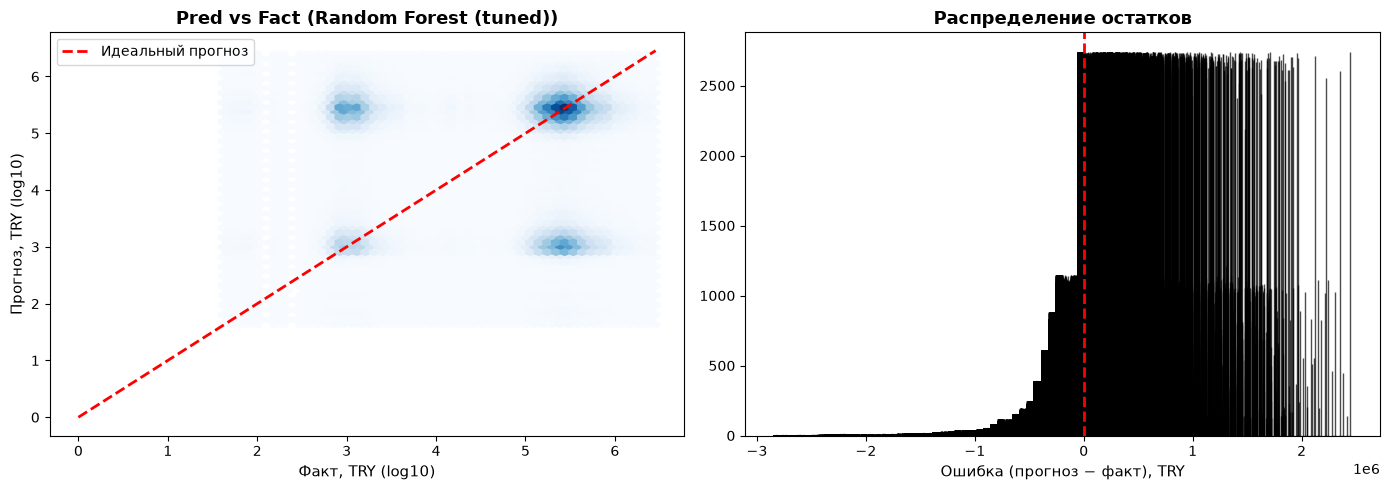


📊 Статистики остатков:
   Среднее:     -18,464.46 TRY
   Медиана:     3.07 TRY
   Стд. откл.:  413,630.85 TRY


In [67]:
# Определяем, какие данные использовать (scaled или нет)
if 'Ridge' in best_name:
    Xte = X_test_scaled
else:
    Xte = X_test

y_pred_test = best_model.predict(Xte)

# Переводим в исходные TRY
y_test_try  = np.expm1(y_test.values)
y_pred_try  = np.expm1(y_pred_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Pred vs Fact (используем полные массивы, hexbin сам их сгруппирует)
axes[0].hexbin(np.log10(y_test_try + 1), 
               np.log10(y_pred_try + 1), 
               gridsize=50, cmap='Blues', mincnt=1)

max_val = max(y_test_try.max(), y_pred_try.max())
axes[0].plot([0, np.log10(max_val + 1)], [0, np.log10(max_val + 1)], 'r--', lw=2, label='Идеальный прогноз')
axes[0].set_xlabel('Факт, TRY (log10)', fontsize=11)
axes[0].set_ylabel('Прогноз, TRY (log10)', fontsize=11)
axes[0].set_title(f'Pred vs Fact ({best_name})', fontweight='bold', fontsize=13)
axes[0].legend()

# 2. Остатки
residuals = y_pred_try - y_test_try
axes[1].hist(residuals, bins=80, color='coral', edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='red', lw=2, ls='--')
axes[1].set_xlabel('Ошибка (прогноз − факт), TRY', fontsize=11)
axes[1].set_title('Распределение остатков', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.show()

print(f"\n📊 Статистики остатков:")
print(f"   Среднее:     {residuals.mean():,.2f} TRY")
print(f"   Медиана:     {np.median(residuals):,.2f} TRY")
print(f"   Стд. откл.:  {residuals.std():,.2f} TRY")

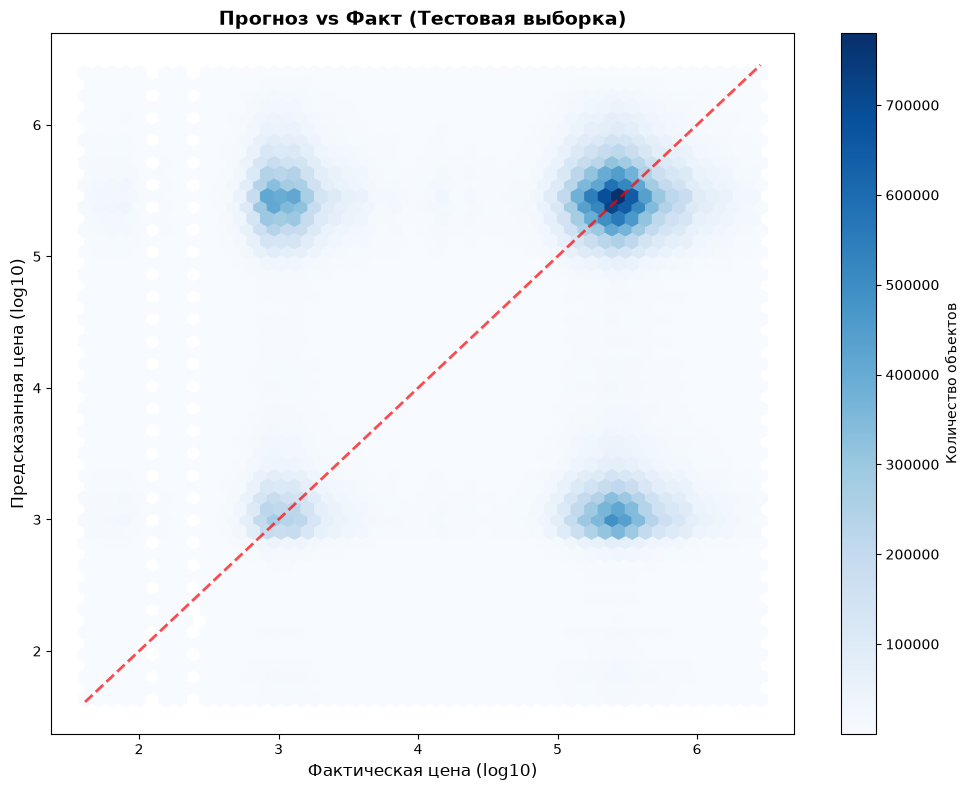

In [69]:
# Переводим в исходный масштаб (TRY), а затем берем log10 для соответствия подписям осей
y_test_log10 = np.log10(np.expm1(y_test.values) + 1)
y_pred_log10 = np.log10(np.expm1(y_pred_test) + 1)

fig, axes = plt.subplots(1, 1, figsize=(10, 8))
hexbin = axes.hexbin(
    y_test_log10,
    y_pred_log10,
    gridsize=50, 
    cmap='Blues', 
    mincnt=1
)
axes.set_xlabel('Фактическая цена (log10)', fontsize=12)
axes.set_ylabel('Предсказанная цена (log10)', fontsize=12)
axes.set_title('Прогноз vs Факт (Тестовая выборка)', fontsize=14, fontweight='bold')
plt.colorbar(hexbin, label='Количество объектов')

# Добавьте линию идеального прогноза
min_val = min(y_test_log10.min(), y_pred_log10.min())
max_val = max(y_test_log10.max(), y_pred_log10.max())
axes.plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.7, linewidth=2)

plt.tight_layout()
plt.show()

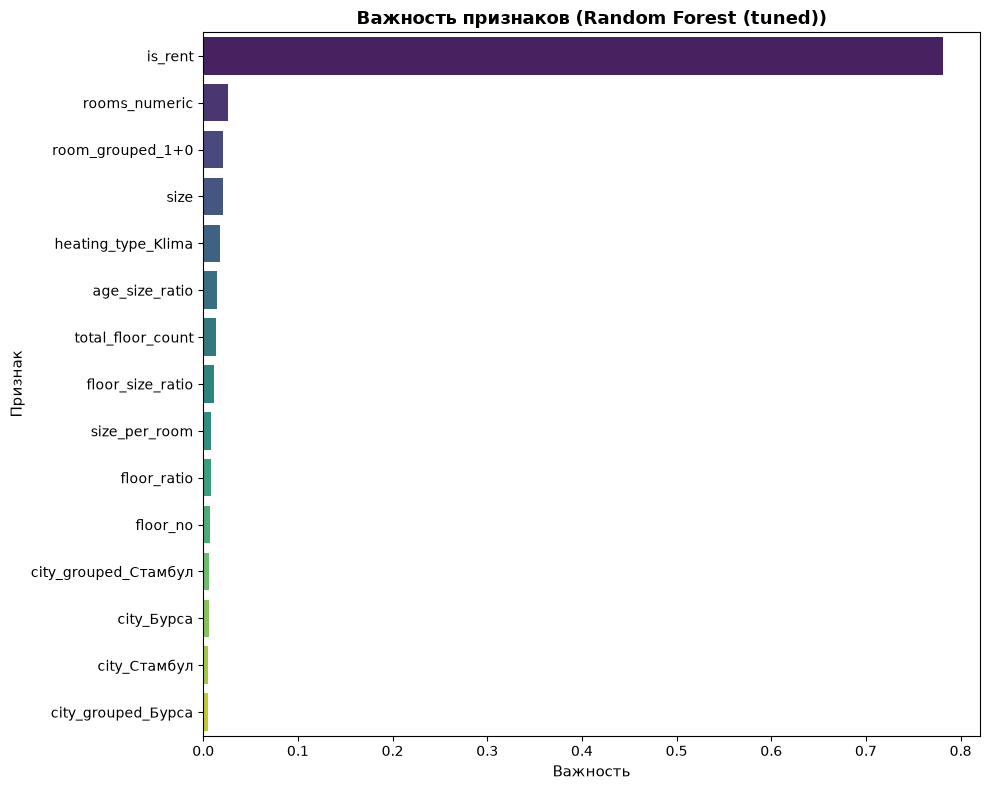


📋 Топ-10 важных признаков (Random Forest (tuned)):
           feature  importance
           is_rent    0.781424
     rooms_numeric    0.026318
  room_grouped_1+0    0.021055
              size    0.020591
heating_type_Klima    0.018198
    age_size_ratio    0.014117
 total_floor_count    0.013140
  floor_size_ratio    0.011485
     size_per_room    0.008020
       floor_ratio    0.007699


In [70]:
fig, ax = plt.subplots(figsize=(10, 8))

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    title = f'Важность признаков ({best_name})'
    xlabel = 'Важность'
elif hasattr(best_model, 'coef_'):
    importances = np.abs(best_model.coef_)
    title = f'Коэффициенты модели ({best_name})'
    xlabel = '|Коэффициент|'
else:
    importances = None

feature_cols = list(X_train.columns)

if importances is not None:
    imp_df = (pd.DataFrame({'feature': feature_cols, 'importance': importances})
              .sort_values('importance', ascending=False)
              .head(15))
    
    sns.barplot(data=imp_df, y='feature', x='importance', ax=ax, palette='viridis')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Признак', fontsize=11)
    plt.tight_layout()
    plt.show()
    
    print(f"\n📋 Топ-10 важных признаков ({best_name}):")
    print(imp_df.head(10).to_string(index=False))

In [71]:
# Сохраняем лучшую модель и метаданные
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(best_name, 'best_model_name.pkl')
joblib.dump(all_results_sorted, 'results_df.pkl')

# Метаданные для формы приложения (медианы/моды train)
sample_input = X_train.median(numeric_only=True).to_dict()
for col in X_train.select_dtypes(include=['object']).columns:
    sample_input[col] = X_train[col].mode()[0]
joblib.dump(sample_input, 'sample_input.pkl')
joblib.dump(list(X_train.columns), 'feature_columns_app.pkl')

print("💾 Сохранено:")
print("   • best_model.pkl — лучшая модель")
print("   • best_model_name.pkl — имя лучшей модели")
print("   • results_df.pkl — таблица метрик всех моделей")
print("   • sample_input.pkl — пример входных данных для приложения")
print("   • feature_columns_app.pkl — список признаков")
print("\n✅ Этап 3 завершён!")

💾 Сохранено:
   • best_model.pkl — лучшая модель
   • best_model_name.pkl — имя лучшей модели
   • results_df.pkl — таблица метрик всех моделей
   • sample_input.pkl — пример входных данных для приложения
   • feature_columns_app.pkl — список признаков

✅ Этап 3 завершён!


In [72]:
# Анализ линейных моделей
linear_models = ['Ridge', 'Lasso', 'Ridge']

for model_name in linear_models:
    if model_name in final_models or model_name in models:
        model = final_models.get(model_name, models[model_name])
        
        coefficients = pd.DataFrame({
            'feature': X_train.columns,
            'coefficient': model.coef_
        }).sort_values('coefficient', key=abs, ascending=False)
        
        print(f"\n📊 Коэффициенты {model_name}:")
        print("\nТоп-10 положительных:")
        print(coefficients[coefficients['coefficient'] > 0].head(10).to_string(index=False))
        print("\nТоп-10 отрицательных:")
        print(coefficients[coefficients['coefficient'] < 0].head(10).to_string(index=False))


📊 Коэффициенты Ridge:

Топ-10 положительных:
                                     feature  coefficient
                            floor_size_ratio     1.684871
                              age_size_ratio     1.374814
                        heating_type_Фанкойл     1.089346
                     sub_type_Фермерский дом     0.787165
                    sub_type_Квартира у воды     0.786876
                                city_Карабюк     0.736470
                            room_grouped_6+1     0.521756
                            room_grouped_5+2     0.498010
                            room_grouped_4+1     0.488479
heating_type_Merkezi Sistem (Isı Payı Ölçer)     0.477014

Топ-10 отрицательных:
                  feature  coefficient
                  is_rent    -5.051483
         room_grouped_1+0    -2.898175
      sub_type_Кооператив    -0.776556
           city_Гюмюшхане    -0.670914
         room_grouped_1+1    -0.643457
            city_Кыршехир    -0.626742
             city_Би

In [73]:
print("="*80)
print(" ФИНАЛЬНЫЙ ВЫБОР МОДЕЛИ")
print("="*80)

# Критерии выбора
best_model_row = all_results_sorted.iloc[0]
best_model_name = best_model_row['Модель']

print(f"\n✅ Выбранная модель: {best_model_name}")
print(f"\n📈 Метрики качества:")
print(f"   • R² (TRY):    {best_model_row['R²_TRY']:.4f}")
print(f"   • MAE (TRY):   {best_model_row['MAE_TRY']:,.2f} TRY")
print(f"   • RMSE (TRY):  {best_model_row['RMSE_TRY']:,.2f} TRY")
print(f"   • MAPE (TRY):  {best_model_row['MAPE_TRY']:.2f}%")

print(f"\n📋 Обоснование выбора:")
print(f"   1. Наивысший R² ({best_model_row['R²_TRY']:.4f}) — модель объясняет {best_model_row['R²_TRY']*100:.1f}% дисперсии цены")
print(f"   2. Наименьшая MAPE ({best_model_row['MAPE_TRY']:.2f}%) — средняя ошибка прогноза в процентах")
print(f"   3. {'Линейная модель — быстрая и интерпретируемая' if 'Ridge' in best_model_name or 'Lasso' in best_model_name else 'Ансамблевая модель — устойчива к переобучению'}")
print(f"   4. {'Быстрое предсказание' if 'Ridge' in best_model_name or 'Lasso' in best_model_name else 'Высокая точность прогноза'}")

print("\n" + "="*80)

 ФИНАЛЬНЫЙ ВЫБОР МОДЕЛИ

✅ Выбранная модель: Random Forest (tuned)

📈 Метрики качества:
   • R² (TRY):    0.7535
   • MAE (TRY):   64,222.88 TRY
   • RMSE (TRY):  161,164.84 TRY
   • MAPE (TRY):  663.94%

📋 Обоснование выбора:
   1. Наивысший R² (0.7535) — модель объясняет 75.3% дисперсии цены
   2. Наименьшая MAPE (663.94%) — средняя ошибка прогноза в процентах
   3. Ансамблевая модель — устойчива к переобучению
   4. Высокая точность прогноза



In [75]:
# Получение лучшей модели
if best_model_name in final_models:
    best_model = final_models[best_model_name]
elif best_model_name in models:
    best_model = models[best_model_name]

# Сохранение модели
joblib.dump(best_model, 'best_model.pkl')
print(f"✅ Модель сохранена: best_model.pkl")

# Сохранение всех артефактов
artifacts = {
    'model': best_model,
    'model_name': best_model_name,
    'scaler': scaler,
    'features_to_scale': features_to_scale,
    'feature_columns': feature_columns,
    'metrics': best_model_row.to_dict()
}

joblib.dump(artifacts, 'model_artifacts.pkl')
print(f"✅ Артефакты сохранены: model_artifacts.pkl")

# Сохранение результатов
all_results.to_csv('model_comparison_results.csv', index=False)
print(f"✅ Результаты сохранены: model_comparison_results.csv")

print("\n🎉 Этап 3 завершен!")

✅ Модель сохранена: best_model.pkl
✅ Артефакты сохранены: model_artifacts.pkl
✅ Результаты сохранены: model_comparison_results.csv

🎉 Этап 3 завершен!
